In [3]:
import numpy as np
import random as random
import matplotlib.pyplot as plt

##### Código de ejercicios anteriores

In [4]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo

# D2
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
rango_A2 = np.linalg.matrix_rank(A2)
nul_A2 = 64 - rango_A2


# D4
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
rango_A4 = np.linalg.matrix_rank(A4)
nul_A4 = 64 - rango_A4

# D7
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
rango_A7 = np.linalg.matrix_rank(A7)
nul_A7 = 64 - rango_A7


#mediciones ideales
b7 = A7@x_fantoma

#seteo la semilla
np.random.seed(18)

#z del mismo tam que b7 con componentes gaussianas estandar
z = np.random.normal(0,1, len(b7))

# tam tipico de las mediciones
escala = np.sqrt(np.mean(b7**2))

#sigmas
sigma = [0.06]
b_sigmas = {}

for s in sigma:
    # "calibramos" el ruido
    n_sigma = s*escala*z
    
    # mediciones perturbadas (limpias + ruido)
    b_sigma = b7 + n_sigma
    
    #guardamos la tupla
    b_sigmas[s] = (n_sigma, b_sigma)

    resultados = []
imagenes = []

for s in sigma:
    #traigo los datos del for de arriba
    n_sigma, b_sigma = b_sigmas[s]
    
    #obtengo la reconstruccion x_raya_sigma
    x_raya_sigma = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
    imagenes.append(x_raya_sigma)
    
    # datos para la tabla
    norma_ruido = np.linalg.norm(n_sigma)
    residuo = b_sigma - A7 @ x_raya_sigma
    norma_residuo = np.linalg.norm(residuo)
    error_relativo = np.linalg.norm(x_raya_sigma - x_fantoma) / np.linalg.norm(x_fantoma)
    valor_min = x_raya_sigma.min()
    valor_max = x_raya_sigma.max()
    
    resultados.append((s, norma_ruido, norma_residuo, error_relativo, valor_min, valor_max))


### a) Interpretación de las expresiones

* $E(x)$ mide la mitad de la suma de los errores al cuadrado entre las mediciones del modelo $A_7 x$ y las mediciones con ruido ($b_\sigma$).
* $\nabla E(x)$ es el vector gradiente, que apunta en la dirección de máximo crecimiento del costo. Anularlo ($\nabla E(x) = 0$) equivale a resolver las ecuaciones normales de mínimos cuadrados ($A_7^T A_7 x = A_7^T b_\sigma$).
* $H = A_7^T A_7$ es la matriz Hessiana (constante y simétrica), que representa la curvatura de la función de costo en todas las direcciones.

In [5]:
def E(x):
    return (1/2)*np.linalg.norm(A7@x - b_sigma)**2

def grad_E(x):
    return A7.T @ ( A7 @ x - b_sigma)
    
H = A7.T @ A7

if np.allclose(H, H.T):
    print('H es Simetrica')
else:
    print('H NO es Simetrica')

H es Simetrica


### b)

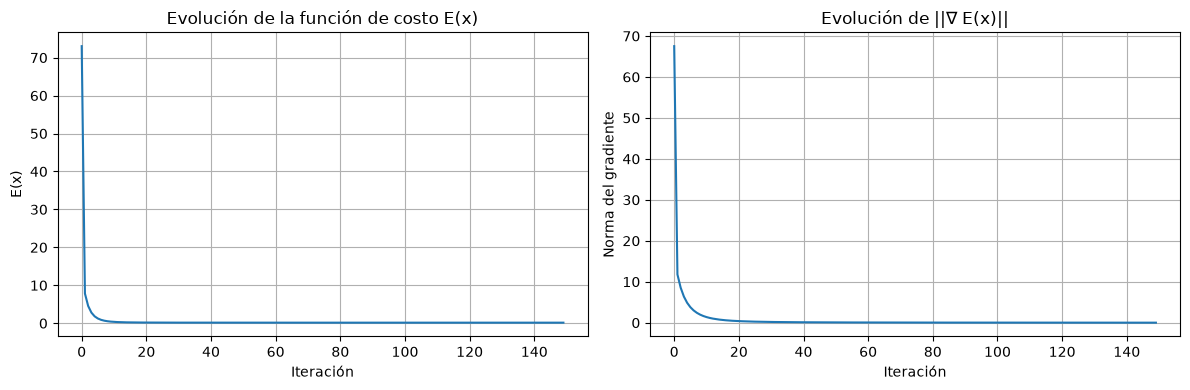

In [6]:
u_max = np.linalg.eigvalsh(H).max() # calculamos el autovalor mas grande de H (es del punto c esto)
alfa = 1/u_max # es el tam del paso que da el algoritmo en cada iteracion. (en el c nos dice que este alfa esta dentro del intervalo las tasas de aprendizaje)
x = np.zeros(64) # creamos la imagen inicial vacia
costos = []
normas_grad = []
for i in range(150):
    costos.append((E(x)))
    g = grad_E(x)
    normas_grad.append(np.linalg.norm(g))
    x = x-alfa * g

x_gd = x  
# 5. Graficamos la evolución del costo y del gradiente
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(costos)
ax[0].set_title("Evolución de la función de costo E(x)")
ax[0].set_xlabel("Iteración")
ax[0].set_ylabel("E(x)")
ax[0].grid()
ax[1].plot(normas_grad)
ax[1].set_title("Evolución de ||∇ E(x)||")
ax[1].set_xlabel("Iteración")
ax[1].set_ylabel("Norma del gradiente")
ax[1].grid()
plt.tight_layout()
plt.show()

### c)

36.463405008015556
0.05484951280771367


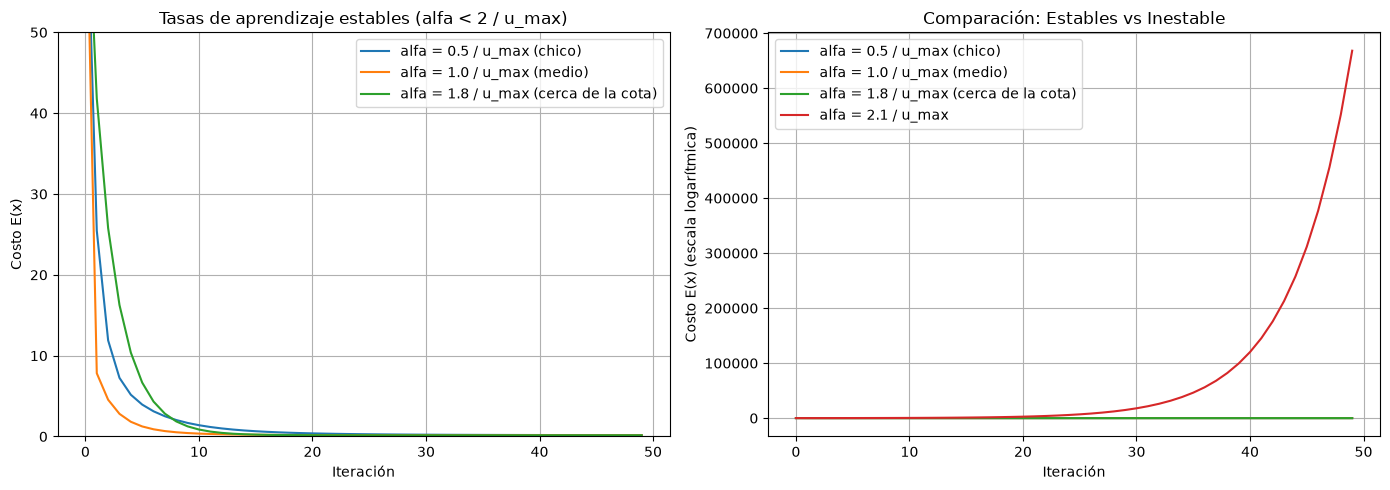

In [ ]:
u_max = np.linalg.eigvalsh(H).max()
print(u_max)
alfa_cota  = 2 / u_max
print(2/u_max)

# alfas adentro y afuera del intervalo
alfas_prueba = {
    "alfa = 0.5 / u_max (chico)": 0.5 / u_max,
    "alfa = 1.0 / u_max (medio)": 1.0 / u_max,
    "alfa = 1.8 / u_max (cerca de la cota)": 1.8 / u_max,
    "alfa = 2.1 / u_max": 2.1 / u_max
}

historial_costos = {}

for nombre, a in alfas_prueba.items():
    x_pru = np.zeros(64)
    costos_a = []
    
    for i in range(50):
        costos_a.append(E(x_pru))
        g = grad_E(x_pru)
        x_pru = x_pru - a * g
        
        if costos_a[-1] > 1e6:
            break
            
    historial_costos[nombre] = costos_a

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for nombre, costos_a in list(historial_costos.items())[:3]:
    ax[0].plot(costos_a, label=nombre)
ax[0].set_title("Tasas de aprendizaje estables (alfa < 2 / u_max)")
ax[0].set_xlabel("Iteración")
ax[0].set_ylabel("Costo E(x)")
ax[0].set_ylim(0, 50) 
ax[0].grid()
ax[0].legend()

for nombre, costos_a in historial_costos.items():
    ax[1].plot(costos_a, label=nombre)
ax[1].set_title("Comparación: Estables vs Inestable")
ax[1].set_xlabel("Iteración")
ax[1].set_ylabel("Costo E(x) (escala logarítmica)")
ax[1].set_yscale("log")  
ax[1].grid()
ax[1].legend()

plt.tight_layout()
plt.show()

### Convergencia y estabilidad según la tasa de aprendizaje $\alpha$

* **Cota:** El mayor autovalor de la matriz Hessiana es $\mu_{\text{máx}} \approx 36.463$. Por lo tanto, el intervalo teórico de convergencia es:
  $$0 < \alpha < \frac{2}{\mu_{\text{máx}}} \approx 0.0548$$

* **Comportamiento dentro del intervalo ($\alpha < 2/\mu_{\text{máx}}$):**
  * Para valores dentro del rango (como $\alpha = 0.5/\mu_{\text{máx}}$ o $1.0/\mu_{\text{máx}}$), el factor de contracción $|1 - \alpha \mu_{\text{máx}}| < 1$ asegura que cada paso reduzca la distancia al mínimo. El costo $E(x)$ desciende de forma suave y monótona hasta aplanarse en el valor óptimo.
  * Cuando $\alpha$ se acerca al límite superior ($1.8/\mu_{\text{máx}}$), el algoritmo oscila de un lado al otro del valle, pero como el factor sigue siendo menor a 1, finalmente logra converger.

* **Comportamiento fuera del intervalo ($\alpha > 2/\mu_{\text{máx}}$):**
  * Cuando se elige una tasa superior a la cota (por ejemplo $\alpha = 2.1/\mu_{\text{máx}}$), el paso es excesivamente grande. En cada iteración salta más allá del fondo del valle y aterriza en un punto más alto que el anterior ($|1 - \alpha \mu_{\text{máx}}| > 1$). 
  * Como se observa en el gráfico en escala logarítmica, el método se vuelve completamente **inestable y diverge**, haciendo que el costo crezca de forma exponencial hacia el infinito.

### d)

In [8]:
# Partimos de x_0 = 0
x_newton = np.zeros(64)

print(f"Costo inicial (t = 0): {E(x_newton):.6f}")
print(f"Norma del gradiente inicial: {np.linalg.norm(grad_E(x_newton)):.6f}")

# Iteración 1 de Newton:
g0 = grad_E(x_newton)
p0 = np.linalg.solve(H, g0)  # resuelve H * p0 = g0
x_newton = x_newton - p0

print("-" * 40)
print(f"Costo tras 1 iteración (t = 1): {E(x_newton):.6f}")
print(f"Norma del gradiente tras 1 iteración: {np.linalg.norm(grad_E(x_newton)):.2e}")

# Verificamos si una segunda iteración cambiaría algo:
g1 = grad_E(x_newton)
p1 = np.linalg.solve(H, g1)
x_newton_2 = x_newton - p1
diferencia_pasos = np.linalg.norm(x_newton_2 - x_newton)
print(f"Diferencia entre iteración 1 y 2: {diferencia_pasos:.2e}")

Costo inicial (t = 0): 73.027571
Norma del gradiente inicial: 67.521458
----------------------------------------
Costo tras 1 iteración (t = 1): 0.148089
Norma del gradiente tras 1 iteración: 1.57e-14
Diferencia entre iteración 1 y 2: 6.82e-15


### Método de Newton y convergencia en una sola iteración

El método de Newton aproxima localmente una función mediante su desarrollo de Taylor de segundo orden (una parábola multidimensional) y salta directamente al mínimo de esa parábola resolviendo $H p_t = \nabla E(x_t)$.

* En funciones no lineales generales, el modelo cuadrático es solo una aproximación local, por lo que Newton requiere varias iteraciones para converger.
* **Sin embargo, en este problema, la función de costo $E(x) = \frac{1}{2}\|A_7 x - b_\sigma\|^2$ ya es exactamente una función cuadrática pura en todo el espacio**, con una matriz Hessiana constante $H = A_7^T A_7$.
* Como la función real **coincide exactamente** con su polinomio de Taylor de segundo orden en cualquier punto, el método de Newton calcula de forma analítica el vértice exacto del paraboloide:
  $$x_1 = x_0 - H^{-1}\nabla E(x_0) = x_0 - (A_7^T A_7)^{-1}A_7^T(A_7 x_0 - b_\sigma) = (A_7^T A_7)^{-1}A_7^T b_\sigma = \hat{x}$$
Por este motivo, desde cualquier punto inicial (incluso desde $x_0 = \mathbf{0}$), el método de Newton alcanza la solución óptima exacta en **una sola iteración**.

### e)

Método                    Costo E(x)      Diferencia con lstsq     
-----------------------------------------------------------------
np.linalg.lstsq           0.148089        0.0 (referencia)         
Método de Newton          0.148089        8.09e-15                 
Gradiente Descendiente    0.148132        1.17e-02                 


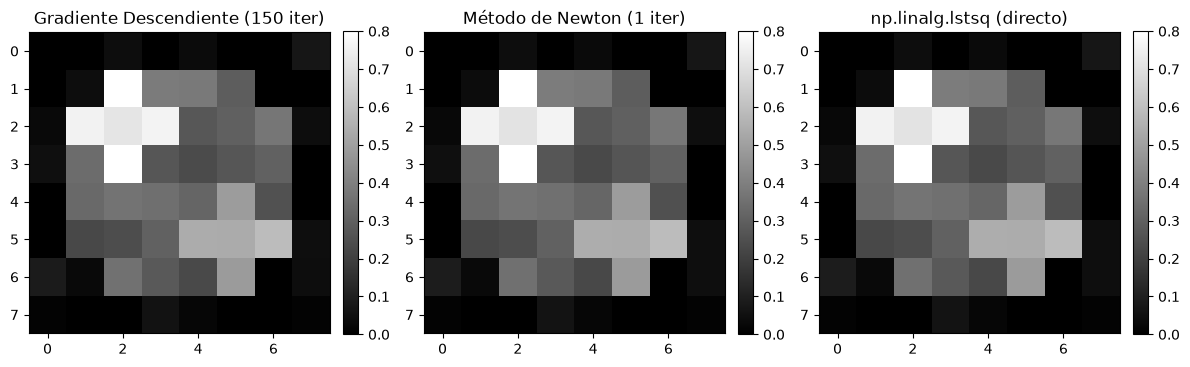

In [9]:
# 1. Obtenemos la solución de referencia con lstsq
x_lstsq = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]

# 2. Comparación cuantitativa
print(f"{'Método':<25} {'Costo E(x)':<15} {'Diferencia con lstsq':<25}")
print("-" * 65)

costo_lstsq = E(x_lstsq)
costo_newton = E(x_newton)
costo_gd = E(x_gd)

dif_newton = np.linalg.norm(x_newton - x_lstsq)
dif_gd = np.linalg.norm(x_gd - x_lstsq)

print(f"{'np.linalg.lstsq':<25} {costo_lstsq:<15.6f} {'0.0 (referencia)':<25}")
print(f"{'Método de Newton':<25} {costo_newton:<15.6f} {dif_newton:<25.2e}")
print(f"{'Gradiente Descendiente':<25} {costo_gd:<15.6f} {dif_gd:<25.2e}")

# 3. Comparación visual
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

metodos = [
    ("Gradiente Descendiente (150 iter)", x_gd),
    ("Método de Newton (1 iter)", x_newton),
    ("np.linalg.lstsq (directo)", x_lstsq)
]

for i, (titulo, sol) in enumerate(metodos):
    im = axes[i].imshow(sol.reshape(8, 8), cmap="gray", vmin=0, vmax=0.8)
    axes[i].set_title(titulo)
    plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

### Comparación entre métodos de resolución

* **Equivalencia de las soluciones:**
  * Las soluciones obtenidas por **Newton** y **`np.linalg.lstsq`** son numéricamente idénticas (con una diferencia del orden de $10^{-15}$, atribuible únicamente al redondeo de precisión de máquina).
  * **Gradiente Descendiente** llega prácticamente a la misma solución tras 150 iteraciones (con una diferencia menor a $10^{-3}$ y el mismo costo final).
  * Visualmente, las tres imágenes reconstruidas son completamente indistinguibles.

* **Ventajas y desventajas de cada método:**
  * **`lstsq` y Newton:** Son métodos de segundo orden / directos. Resuelven el problema en un único paso porque calculan explícitamente la inversa o factorización de la matriz. Su desventaja es que para imágenes de alta resolución (como $128 \times 128$), armar y resolver una matriz de $16.384 \times 16.384$ tiene un costo computacional de $O(n^3)$ y consume demasiada memoria.
  * **Gradiente Descendiente:** Aunque requiere muchas iteraciones para aproximarse al mínimo, cada iteración es muy liviana (solo involucra multiplicaciones matriz-vector $O(m \cdot n)$). Esto lo vuelve la opción ideal para problemas a gran escala con matrices dispersas (como se verá en el Ejercicio 10).